# Лабораторна робота 1

Варіант 3.

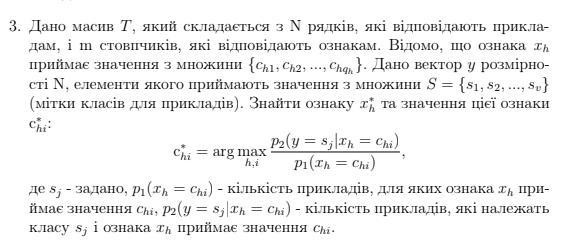

In [177]:
import pandas as pd
import numpy as np
import itertools
from IPython.display import display, Math


In [178]:
T = pd.read_csv("./dataset.csv", index_col=0)
print("Масив T:")
T

Масив T:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y


In [179]:
X = pd.DataFrame([
    [col, T[col].unique()] for col in T.columns
], columns=['$x_h$','$c_h$'])
display(Math(r"\text{Ознаки } x_h \text{ і значення, яких можуть набувати } c_{hi}:"))
X

<IPython.core.display.Math object>

,$x_h$,$c_h$
0,Gender,"[Male, Female, nan]"
1,Married,"[No, Yes, nan]"
2,Dependents,"[0, 1, 2, 3+, nan]"
3,Education,"[Graduate, Not Graduate]"
4,Self_Employed,"[No, Yes, nan]"
5,ApplicantIncome,"[5849, 4583, 3000, 2583, 6000, 5417, 2333, 303..."
6,CoapplicantIncome,"[0.0, 1508.0, 2358.0, 4196.0, 1516.0, 2504.0, ..."
7,LoanAmount,"[nan, 128.0, 66.0, 120.0, 141.0, 267.0, 95.0, ..."
8,Loan_Amount_Term,"[360.0, 120.0, 240.0, nan, 180.0, 60.0, 300.0,..."
9,Credit_History,"[1.0, 0.0, nan]"


In [180]:
yname, S = X.loc[X['$c_h$'].apply(len).idxmin()]
y = T[yname]
print(f'Множину S в роботі задано як {set(S)}, а вектор y як колонку з T "{y.name}".')

Множину S в роботі задано як {'Not Graduate', 'Graduate'}, а вектор y як колонку з T "Education".


In [181]:
s_j = y.iat[0]
x_hstar, c_histar, cmax_current = 0, 0, 0
masky = y == s_j
for xc in X.values:
    masks = np.fromiter((T[xc[0]] == c_hi if not pd.isna(c_hi) else T[xc[0]].isna() for c_hi in xc[1]), dtype=object)
    p1 = np.fromiter((np.sum(mask) for mask in masks), dtype=int)
    p2 = np.fromiter((np.sum(mask & masky) for mask in masks), dtype=int)
    cmax = p2 / p1
    if np.max(cmax) > cmax_current:
        c_histar = xc[1][cmax.argmax()]
        x_hstar = xc[0]
        cmax_current = np.max(cmax)

In [182]:
h = X['$x_h$'].loc[X['$x_h$'] == x_hstar].index[0]
c_h = X['$c_h$'].iloc[h]
i = np.where(c_h == c_histar if not pd.isna(c_histar) else pd.isna(c_h))[0][0]
display(Math(r"\text{Отже, } h=" f"{h}, i={i}, " r"x_h^*=" f"{x_hstar}" r"\text{ і } c_{hi}^*=" f"{c_histar}"))

<IPython.core.display.Math object>